# 08 A second test: was the fine-tuned win luck?

**Why this notebook.** On the first test (notebook 06), the fine-tuned ResNet18 (87.9 %) beat the frozen
one that we had chosen on validation (83.0 %), while validation said the opposite (85.4 % against
88.1 %). With 220 paintings, a score moves by about 5 points just by chance. To see whether the
fine-tuned win was luck, we drew **220 new paintings** (44 per style) that no model and no notebook had
ever seen (`scripts/make_second_test.py`):

- none of our 1 500 paintings, and only WikiArt shards that we never opened;
- no painter known from our 1 500 paintings: the models never saw these painters;
- the same processing as our data (224 x 224 centre crop), and a near-duplicate check against our
  1 500 paintings.

**Rules, written before looking at any result.**

1. The models are trained again with the exact recipes and seeds of notebook 06: nothing is tuned here.
2. The second test is used **once**, for every model.
3. Our choice stays the frozen ResNet18, made on validation before both tests. If the fine-tuned model is
   again clearly better (paired interval entirely above 0), we say so and recommend to retry
   fine-tuning.
4. We also pool both tests (440 paintings) for a tighter comparison: to report, not to choose.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from museum_guide.baselines import hand_features_batch, make_forest
from museum_guide.config import FAST_RUN, ROOT, set_seed
from museum_guide.data import UNKNOWN_ARTIST, channel_stats, class_names, load_images, load_metadata, load_split_images, standardise
from museum_guide.evaluation import (bootstrap_ci, confusion_matrix, load_results, paired_bootstrap, per_class_report,
                                     save_results)
from museum_guide.features import cached_features
from museum_guide.models import ResNetClassifier
from museum_guide.plots import PALETTE, save_figure
from museum_guide.recipes import FINETUNE, MLP_REGULARISED, train_finetune, train_head, train_mlp
from museum_guide.training import make_loaders, predict

set_seed()
SEEDS = [0] if FAST_RUN else [0, 1, 2]
TEST2_DIR = ROOT / "data" / "wikiart_test2"

images224, meta = load_split_images(224, include_test=True)
images32, _ = load_split_images(32, include_test=True)
masks = {s: (meta["split"] == s).to_numpy() for s in ("train", "val", "test")}
y = {s: images224[s][1] for s in masks}

meta2 = load_metadata(TEST2_DIR)
info2 = json.loads((TEST2_DIR / "subset_info.json").read_text(encoding="utf-8"))
assert class_names(meta2) == class_names(meta), "same styles, same order"
x2 = {224: load_images(meta2, 224, TEST2_DIR), 64: load_images(meta2, 64, TEST2_DIR), 32: load_images(meta2, 32, TEST2_DIR)}
y["test2"] = torch.tensor(meta2["label_idx"].to_numpy())

known = set(meta.loc[meta["artist"] != UNKNOWN_ARTIST, "artist"])
print("second test:", len(meta2), "paintings", dict(meta2["label"].value_counts().sort_index()))
print("WikiArt shards:", info2["shards"], "| shards shared with our data:", sorted(set(info2["shards"]) & set(meta["shard"])))
print("paintings shared with our data:", len(set(meta2["id"]) & set(meta["id"])),
      "| painters known from our data:", len(set(meta2["artist"]) & known),
      f"| Unknown Artist: {(meta2['artist'] == UNKNOWN_ARTIST).mean():.0%} (first test: "
      f"{(meta.loc[masks['test'], 'artist'] == UNKNOWN_ARTIST).mean():.0%})",
      "| near-duplicates removed:", len(info2["near_duplicates_removed"]))

second test: 220 paintings {'Baroque': np.int64(44), 'Cubism': np.int64(44), 'Impressionism': np.int64(44), 'Pop_Art': np.int64(44), 'Ukiyo_e': np.int64(44)}
WikiArt shards: [19, 22, 32, 37, 56, 58] | shards shared with our data: []
paintings shared with our data: 0 | painters known from our data: 0 | Unknown Artist: 89% (first test: 63%) | near-duplicates removed: 0


**What we see.** 220 paintings, 44 per style, from 6 WikiArt shards that our data never used. No painting
and no painter in common with our 1 500 paintings, and no near-duplicate. 89 % are by "Unknown Artist"
(63 % in the first test): WikiArt names only 129 painters, and for 4 of our 5 styles all of them were
already in our data. So every painting is by a painter that the models never saw.

## 1. The same models, trained again

**What we do.** We train every model again exactly as in notebook 06: the random forest with the setting
chosen on validation, and the three neural models with their recipes and seeds 0, 1 and 2. Their
validation accuracy must be exactly the one of notebook 06: then they are the same models.

In [2]:
setting = load_results("06_final")["classical_settings"]["random forest on hand-made features"]
hand = hand_features_batch(load_images(meta, 64))
hand2 = hand_features_batch(x2[64])
forest = make_forest(**setting).fit(hand[masks["train"]], y["train"].numpy())

mean32, std32 = channel_stats(images32["train"][0])
mlp_data = {s: standardise(images32[s][0], mean32, std32) for s in masks}
mlp_data["test2"] = standardise(x2[32], mean32, std32)
mlp_loaders = make_loaders(mlp_data["train"], y["train"], mlp_data["val"], y["val"], batch_size=64)
img_loaders = make_loaders(*images224["train"], *images224["val"], batch_size=32, eval_batch_size=128)
features, _ = cached_features(meta)
feat = {s: features[torch.tensor(m)] for s, m in masks.items()}

MLP, RF = "regularised MLP on pixels", "random forest on hand-made features"
FROZEN, FT = "ResNet18 frozen + linear head", "ResNet18 fine-tuned (layer4)"
runs = {MLP: [], FROZEN: [], FT: []}
for seed in SEEDS:
    model, _ = train_mlp(mlp_loaders, seed=seed, **{k: v for k, v in MLP_REGULARISED.items() if k != "size"})
    runs[MLP].append(model)
    head, _ = train_head(feat["train"], y["train"], feat["val"], y["val"], seed=seed)
    runs[FROZEN].append(ResNetClassifier(train_from=None, head=head).eval())
    model, _ = train_finetune(img_loaders, seed=seed, **(dict(FINETUNE, epochs=2) if FAST_RUN else FINETUNE))
    runs[FT].append(model)

inputs = {MLP: {**mlp_data}, FROZEN: {**{s: images224[s][0] for s in masks}, "test2": x2[224]}}
inputs[FT] = inputs[FROZEN]
PARTS = ("val", "test", "test2")


def predictions(name):
    """{part: [one array of predictions per seed]} (one array for the random forest)."""
    if name == RF:
        X = {"val": hand[masks["val"]], "test": hand[masks["test"]], "test2": hand2}
        return {p: [forest.predict(X[p])] for p in PARTS}
    return {p: [predict(m, make_loaders(inputs[name][p], y[p], inputs[name][p], y[p], eval_batch_size=128).val)[0]
                .argmax(dim=1).numpy() for m in runs[name]] for p in PARTS}


order = [MLP, RF, FROZEN, FT]
preds = {n: predictions(n) for n in order}
truth = {p: y[p].numpy() for p in PARTS}
before = {r["model"]: r["test_acc"] for r in load_results("06_final")["test"]}
check = pd.DataFrame([{"model": n, "val_acc": np.mean([(q == truth["val"]).mean() for q in preds[n]["val"]]),
                       "test_acc_now": np.mean([(q == truth["test"]).mean() for q in preds[n]["test"]]),
                       "test_acc_notebook_06": before[n]} for n in order]).set_index("model")
check["same"] = (check["test_acc_now"] - check["test_acc_notebook_06"]).abs() < 1e-4
check.round(4)

,val_acc,test_acc_now,test_acc_notebook_06,same
model,,,,
regularised MLP on pixels,0.4551,0.4136,0.4136,True
random forest on hand-made features,0.6347,0.6727,0.6727,True
ResNet18 frozen + linear head,0.8813,0.8303,0.8303,True
ResNet18 fine-tuned (layer4),0.8539,0.8788,0.8788,True


**What we see.** The 4 models give exactly the validation and first-test accuracies of notebook 06
(column `same`): these are the same models.

## 2. The second test (measured once)

**What we do.** Every model predicts the 220 new paintings. As in notebook 06: mean accuracy over the 3
seeds, and a 95 % bootstrap interval (seed 0).

In [3]:
rows = []
for n in order:
    row = {"model": n}
    for p, label in (("test", "test 1"), ("test2", "test 2")):
        correct = preds[n][p][0] == truth[p]
        lo, hi = bootstrap_ci(correct)
        row.update({f"{label} acc": np.mean([(q == truth[p]).mean() for q in preds[n][p]]), f"{label} low": lo, f"{label} high": hi})
    rows.append(row)
table = pd.DataFrame(rows).set_index("model")
table.round(3)

,test 1 acc,test 1 low,test 1 high,test 2 acc,test 2 low,test 2 high
model,,,,,,
regularised MLP on pixels,0.414,0.345,0.473,0.418,0.355,0.482
random forest on hand-made features,0.673,0.609,0.736,0.636,0.573,0.700
ResNet18 frozen + linear head,0.830,0.786,0.886,0.841,0.782,0.877
ResNet18 fine-tuned (layer4),0.879,0.841,0.927,0.877,0.836,0.923


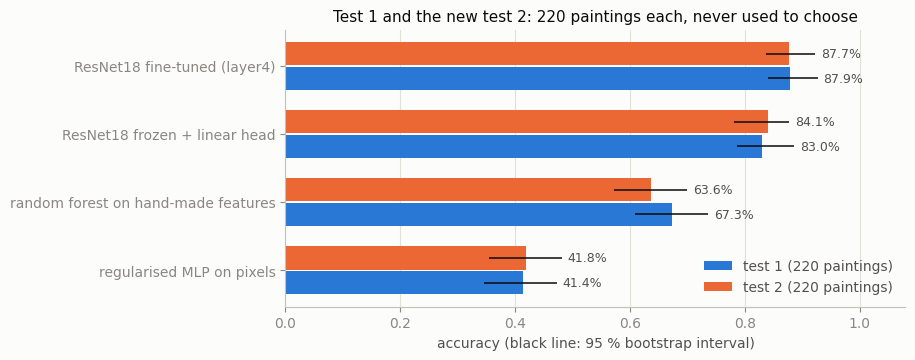

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
yy = np.arange(len(order))
for k, (label, color, dy) in enumerate((("test 1", PALETTE[0], -0.18), ("test 2", PALETTE[1], 0.18))):
    ax.barh(yy + dy, table[f"{label} acc"], height=0.34, color=color, label=f"{label} (220 paintings)")
    ax.hlines(yy + dy, table[f"{label} low"], table[f"{label} high"], color="#0b0b0b", linewidth=1.1)
    for j, v in enumerate(table[f"{label} acc"]):
        ax.text(table[f"{label} high"].iloc[j] + 0.01, j + dy, f"{v:.1%}", va="center", color="#52514e", fontsize=9)
ax.set_yticks(yy, order)
ax.set_xlim(0, 1.08)
ax.set_xlabel("accuracy (black line: 95 % bootstrap interval)")
ax.set_title("Test 1 and the new test 2: 220 paintings each, never used to choose")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_figure(fig, "08_second_test")
plt.show()

**Was the fine-tuned win luck?** We compare the pairs on the same paintings (paired bootstrap): on the
second test for each seed, and on both tests pooled (440 paintings, seed 0).

In [5]:
def correct(n, p, k=0):
    return preds[n][p][k] == truth[p]


pairs = [(FROZEN, FT), (FROZEN, RF), (RF, MLP)]
paired = []
for a, b in pairs:
    for k in range(len(SEEDS) if a != RF and b != RF else 1):
        kb = k if b != RF else 0
        paired.append({"A": a, "B": b, "test": "test 2", "seed": SEEDS[k],
                       **paired_bootstrap(correct(a, "test2", k), correct(b, "test2", kb))})
    paired.append({"A": a, "B": b, "test": "test 1 + test 2 (440)", "seed": 0,
                   **paired_bootstrap(np.concatenate([correct(a, "test"), correct(a, "test2")]),
                                      np.concatenate([correct(b, "test"), correct(b, "test2")]))})
paired = pd.DataFrame(paired)
paired.round(3)

,A,B,test,seed,diff,ci_low,ci_high,share_not_better
0,ResNet18 frozen + linear head,ResNet18 fine-tuned (layer4),test 2,0,-0.050,-0.091,-0.009,0.995
1,ResNet18 frozen + linear head,ResNet18 fine-tuned (layer4),test 2,1,-0.045,-0.086,-0.009,0.993
2,ResNet18 frozen + linear head,ResNet18 fine-tuned (layer4),test 2,2,-0.014,-0.059,0.032,0.743
3,ResNet18 frozen + linear head,ResNet18 fine-tuned (layer4),test 1 + test 2 (440),0,-0.050,-0.082,-0.020,1.000
4,ResNet18 frozen + linear head,random forest on hand-made features,test 2,0,0.195,0.127,0.264,0.000
5,ResNet18 frozen + linear head,random forest on hand-made features,test 1 + test 2 (440),0,0.180,0.127,0.230,0.000
6,random forest on hand-made features,regularised MLP on pixels,test 2,0,0.218,0.150,0.286,0.000
7,random forest on hand-made features,regularised MLP on pixels,test 1 + test 2 (440),0,0.241,0.191,0.291,0.000


In [6]:
cm = confusion_matrix(y["test2"], torch.tensor(preds[FROZEN]["test2"][0]), 5)
per_class2 = per_class_report(cm, class_names(meta))
per_class2.round(3)

,recall,precision,f1,images
Baroque,0.955,0.778,0.857,44
Cubism,0.841,0.860,0.851,44
Impressionism,0.795,0.854,0.824,44
Pop_Art,0.614,0.794,0.692,44
Ukiyo_e,0.955,0.875,0.913,44


In [7]:
# The model we now recommend: its errors per style on both tests (seed 0), and every model on the 440 paintings.
both_truth = np.concatenate([truth["test"], truth["test2"]])
cm_ft = confusion_matrix(torch.tensor(both_truth), torch.tensor(np.concatenate([preds[FT]["test"][0], preds[FT]["test2"][0]])), 5)
per_class_ft = per_class_report(cm_ft, class_names(meta))
both_tests = {n: float(np.mean([(np.concatenate([preds[n]["test"][k], preds[n]["test2"][k]]) == both_truth).mean()
                               for k in range(len(preds[n]["test"]))])) for n in order}
print({n: round(v, 3) for n, v in both_tests.items()})
per_class_ft.round(3)

{'regularised MLP on pixels': 0.416, 'random forest on hand-made features': 0.655, 'ResNet18 frozen + linear head': 0.836, 'ResNet18 fine-tuned (layer4)': 0.878}


,recall,precision,f1,images
Baroque,0.942,0.827,0.880,86
Cubism,0.849,0.880,0.864,86
Impressionism,0.819,0.917,0.865,94
Pop_Art,0.816,0.835,0.826,87
Ukiyo_e,1.000,0.967,0.983,87


In [8]:
save_results("08_second_test", {
    "data": {"n": len(meta2), "per_style": meta2["label"].value_counts().sort_index().to_dict(), "shards": info2["shards"],
             "unknown_artist_share": float((meta2["artist"] == UNKNOWN_ARTIST).mean()),
             "near_duplicates_removed": len(info2["near_duplicates_removed"]), "seed": info2["seed"]},
    "reproducibility": check.reset_index().to_dict(orient="records"),
    "table": table.reset_index().to_dict(orient="records"),
    "paired": paired.to_dict(orient="records"),
    "frozen_seed0_per_class_test2": per_class2.reset_index().rename(columns={"index": "style"}).to_dict(orient="records"),
    "both_tests_acc": both_tests,
    "finetuned_seed0_per_class_both_tests": per_class_ft.reset_index().rename(columns={"index": "style"}).to_dict(orient="records"),
})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/08_second_test.json')

**What we see.**

- **The ranking does not change** on the new paintings: fine-tuned ResNet18 **87.7 %** (interval 83.6 to
  92.3), frozen ResNet18 **84.1 %** (78.2 to 87.7), random forest **63.6 %** (57.3 to 70.0), our MLP 41.8 %.
- **The answer to the director is confirmed**: the frozen ResNet is 19.5 points better than the random
  forest on test 2 (interval 12.7 to 26.4), and 18.0 points on both tests pooled (12.7 to 23.0).
- **The fine-tuned win was not luck.** On test 2 it beats the frozen model by 5.0 and 4.5 points for seeds
  0 and 1 (intervals 0.9 to 9.1 and 0.9 to 8.6, entirely above 0), and by 1.4 points for seed 2 (interval
  -3.2 to 5.9). On the 440 test paintings pooled: **+5.0 points (2.0 to 8.2)**; in all 5 000 redraws the
  fine-tuned model is at least as good.
- So our 219 validation paintings were too few to separate the two variants: validation said frozen by
  2.7 points, two independent tests say fine-tuned by 4 to 5 points.

**Decision (rule 3).** The fine-tuned model is clearly better, so we say so and **we now recommend the
fine-tuned ResNet18**. It has the same speed (53 ms per photo) and size (45 MB) as the frozen one; it needs
2 to 4 minutes of training instead of seconds. Because the two tests helped this choice, its test scores
are slightly optimistic. Next time we would choose with cross-validation on train + validation, and keep a
third set of new paintings for the final score.